# 01_nhanes: CDC NHANES (U.S. National Health and Nutrition Examination Survey)

Public, de-identified survey files from CDC/NCHS (wwwn.cdc.gov/nchs/nhanes), downloaded as .XPT by the build scripts. Four Toxoplasma cohorts with three different assays, so they are evaluated separately, never pooled across assays. New in this folder: NHANES 1999-2004 (files LAB17, L17_B, L17_C; IgG tested at ages 6-49).

**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
%run -i datasets/common/protocol.ipynb
%run -i datasets/common/folder_tools.ipynb
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/01_nhanes'
print('working directory:', os.getcwd())

working directory: /home/claude/toxo


## Part 1: build NHANES 1999-2004

NHANES 1999-2000, 2001-2002, 2003-2004: Toxoplasma IgG cohort (adults 18-49; IgG was only tested at ages 6-49).
Label: LBXTO1 (1999-2000, 2003-2004) / LBDTO1 (2001-2002) = Toxoplasma IgG, CDC EIA. Positive = IgG >= 7 IU/mL
(the level at which CDC ran the IgM follow-up test; checked below against the published 1999-2004 seroprevalence).
Output: processed/nhanes_1999_2004.csv
Run from the repo root:  python datasets/01_nhanes/build_nhanes_1999_2004.py

In [2]:
import os
import urllib.request
import numpy as np
import pandas as pd
HERE = os.path.join('datasets', '01_nhanes')
RAW, OUT = os.path.join(HERE, 'raw'), os.path.join(HERE, 'processed')

os.makedirs(RAW, exist_ok=True); os.makedirs(OUT, exist_ok=True)
URL = 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{year}/DataFiles/{name}.xpt'
CYCLES = {'1999-2000': (1999, ''), '2001-2002': (2001, '_B'), '2003-2004': (2003, '_C')}
FILES = {'DEMO': 'DEMO', 'TOXO': {'': 'LAB17', '_B': 'L17_B', '_C': 'L17_C'}, 'HIQ': 'HIQ', 'SMQ': 'SMQ', 'HOQ': 'HOQ',
         'OCQ': 'OCQ', 'HSQ': 'HSQ', 'FSQ': 'FSQ'}

**`get`**

In [3]:
def get(year, name):
    p = os.path.join(RAW, f'{name}.xpt')
    if not os.path.exists(p):
        urllib.request.urlretrieve(URL.format(year=year, name=name), p)
    d = pd.read_sas(p, format='xport')
    for c in d.select_dtypes('float').columns:
        d.loc[(d[c].abs() > 0) & (d[c].abs() < 1e-70), c] = 0.0          # XPT stores 0 as 5.4e-79
    return d

**`yn`**

In [4]:
def yn(s):
    return s.map({1.0: 1.0, 2.0: 0.0})

In [5]:
rows = []
for cyc, (year, suf) in CYCLES.items():
    demo = get(year, 'DEMO' + suf)
    tox = get(year, FILES['TOXO'][suf])
    tox = tox.rename(columns={'LBDTO1': 'LBXTO1'})
    d = demo.merge(tox[['SEQN', 'LBXTO1']], on='SEQN')
    for stem, cols in [('HIQ', ['HID010']), ('SMQ', ['SMQ020', 'SMQ040']), ('HOQ', ['HOD050', 'HOQ065']),
                       ('OCQ', ['OCD240', 'OCQ180']), ('HSQ', ['HSD010']), ('FSQ', [])]:
        try:
            q = get(year, stem + suf)
            d = d.merge(q[['SEQN'] + [c for c in cols if c in q]], on='SEQN', how='left')
        except Exception as e:               # a file missing in a cycle -> columns stay empty
            print('  skip', stem + suf, e)
    d['cycle'] = cyc
    rows.append(d)
d = pd.concat(rows, ignore_index=True)
d = d[d.LBXTO1.notna() & d.RIDAGEYR.between(18, 49)].copy().reset_index(drop=True)

**`col`**

In [6]:
def col(name):
    return d[name] if name in d else pd.Series(np.nan, index=d.index)

In [7]:
out = pd.DataFrame({
    'age': d.RIDAGEYR, 'male': (d.RIAGENDR == 1).astype(float),
    'race_ethnicity': d.RIDRETH1.map({1: 'Mexican American', 2: 'Other Hispanic', 3: 'NH White', 4: 'NH Black', 5: 'Other'}),
    'born_outside_us': col('DMDBORN').map({1: 0.0, 2: 1.0, 3: 1.0}),
    'years_in_us': col('DMDYRSUS').where(col('DMDYRSUS') < 77),
    'education': col('DMDEDUC2').where(col('DMDEDUC2') < 7),
    'poverty_income_ratio': d.INDFMPIR, 'household_size': col('DMDHHSIZ'),
    'spanish_interview': (col('SIALANG') == 2).astype(float),
    'not_us_citizen': col('DMDCITZN').map({1: 0.0, 2: 1.0}),
    'no_health_insurance': 1 - yn(col('HID010')),
    'ever_smoked_100': yn(col('SMQ020')),
    'rooms_in_home': col('HOD050').where(col('HOD050') < 77),
    'home_owned': col('HOQ065').map({1: 1.0, 2: 0.0, 3: 0.0}),
    'self_rated_health': col('HSD010').where(col('HSD010') < 7),
    'cycle': d.cycle,
    'toxo_igg_iu': d.LBXTO1})
out['crowding'] = out.household_size / out.rooms_in_home
out['target_toxo_pos'] = (out.toxo_igg_iu >= 7).astype(int)
out = out.drop(columns=['toxo_igg_iu'])
out.to_csv(os.path.join(OUT, 'nhanes_1999_2004.csv'), index=False)
print(f'NHANES 1999-2004 adults 18-49: n = {len(out):,}, positive = {out.target_toxo_pos.sum():,} ({out.target_toxo_pos.mean():.1%})')
print(out.groupby('cycle').target_toxo_pos.agg(['size', 'mean']).round(3))
print('U.S.-born only:', round(out[out.born_outside_us == 0].target_toxo_pos.mean(), 3))

NHANES 1999-2004 adults 18-49: n = 8,485, positive = 1,235 (14.6%)
           size   mean
cycle                 
1999-2000  2630  0.173
2001-2002  3070  0.135
2003-2004  2785  0.131
U.S.-born only: 0.096


## Part 2: evaluate all four NHANES cohorts

Evaluate every NHANES Toxoplasma cohort with the shared protocol -> results.csv

The 2013-2014, 2009-2014 and NHANES III files are built by the earlier scripts in `scripts/` (`build_bio_features.py`, `build_nhanes3.py`) into `data/processed/`.

In [8]:
import os, re, sys
import pandas as pd
HERE = os.path.join('datasets', '01_nhanes')
DROP = re.compile(r'^(SEQN|seqn|WT.*|SDMV.*|SDP.*|SDST.*|DMDBORN4|cycle)$')
COHORTS = [
    ('nhanes_1999_2004', os.path.join(HERE, 'processed', 'nhanes_1999_2004.csv'), 'target_toxo_pos',
     'Adults 18-49, 1999-2004, CDC EIA IgG >= 7 IU/mL; demographics, housing, insurance, smoking'),
    ('nhanes_2013_2014_markers', os.path.join('data', 'processed', 'nhanes_adult_toxo_bio.csv'), 'target_toxo_pos',
     'Adults 18+, 2013-2014, Bio-Rad IgG >= 33 IU/mL; baseline + lifestyle + 44 markers (the paper)'),
    ('nhanes_2009_2014_pooled', os.path.join('data', 'processed', 'nhanes_adult_toxo_bio_2009_2014.csv'), 'target_toxo_pos',
     'Adults 18+, 2009-2014 pooled, same assay; baseline + markers'),
    ('nhanes_iii_1988_1994', os.path.join('data', 'processed', 'nhanes3_adult_toxo.csv'), 'target_toxo_pos',
     'Adults 18+, 1988-1994; includes cat, garden, meat-frequency, region and water questions'),
]
rows = []
for key, path, label, desc in COHORTS:
    if not os.path.exists(path):
        print('missing', path, '- run its build script first'); continue
    d = pd.read_csv(path)
    y = d[label].astype(int)
    X = clean_features(d.drop(columns=[label] + [c for c in d.columns if DROP.match(c)]))
    res = evaluate(X, y)
    rows.append(summarise(key, X, y, res, dict(description=desc)))
    print(rows[-1])
res = pd.DataFrame(rows)
res.to_csv(os.path.join(HERE, 'results.csv'), index=False)

{'dataset': 'nhanes_1999_2004', 'n': 8485, 'positives': 1235, 'prevalence': 0.146, 'n_features': 15, 'LogReg_auc': 0.72, 'LogReg_sd': 0.018, 'RandomForest_auc': 0.715, 'RandomForest_sd': 0.018, 'XGBoost_auc': 0.718, 'XGBoost_sd': 0.016, 'best_auc': 0.72, 'best_model': 'LogReg', 'description': 'Adults 18-49, 1999-2004, CDC EIA IgG >= 7 IU/mL; demographics, housing, insurance, smoking'}


{'dataset': 'nhanes_2013_2014_markers', 'n': 5006, 'positives': 750, 'prevalence': 0.15, 'n_features': 54, 'LogReg_auc': 0.699, 'LogReg_sd': 0.018, 'RandomForest_auc': 0.718, 'RandomForest_sd': 0.022, 'XGBoost_auc': 0.713, 'XGBoost_sd': 0.015, 'best_auc': 0.718, 'best_model': 'RandomForest', 'description': 'Adults 18+, 2013-2014, Bio-Rad IgG >= 33 IU/mL; baseline + lifestyle + 44 markers (the paper)'}


{'dataset': 'nhanes_2009_2014_pooled', 'n': 14649, 'positives': 2495, 'prevalence': 0.17, 'n_features': 58, 'LogReg_auc': 0.726, 'LogReg_sd': 0.015, 'RandomForest_auc': 0.738, 'RandomForest_sd': 0.011, 'XGBoost_auc': 0.742, 'XGBoost_sd': 0.011, 'best_auc': 0.742, 'best_model': 'XGBoost', 'description': 'Adults 18+, 2009-2014 pooled, same assay; baseline + markers'}


{'dataset': 'nhanes_iii_1988_1994', 'n': 15524, 'positives': 4263, 'prevalence': 0.275, 'n_features': 37, 'LogReg_auc': 0.691, 'LogReg_sd': 0.009, 'RandomForest_auc': 0.706, 'RandomForest_sd': 0.009, 'XGBoost_auc': 0.703, 'XGBoost_sd': 0.008, 'best_auc': 0.706, 'best_model': 'RandomForest', 'description': 'Adults 18+, 1988-1994; includes cat, garden, meat-frequency, region and water questions'}


In [9]:
cols = ['dataset', 'n', 'positives', 'prevalence', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc',
        'best_auc', 'best_model']
res[[c for c in cols if c in res]]

,dataset,n,positives,prevalence,n_features,LogReg_auc,RandomForest_auc,XGBoost_auc,best_auc,best_model
0,nhanes_1999_2004,8485,1235,0.146,15,0.720,0.715,0.718,0.720,LogReg
1,nhanes_2013_2014_markers,5006,750,0.150,54,0.699,0.718,0.713,0.718,RandomForest
2,nhanes_2009_2014_pooled,14649,2495,0.170,58,0.726,0.738,0.742,0.742,XGBoost
3,nhanes_iii_1988_1994,15524,4263,0.275,37,0.691,0.706,0.703,0.706,RandomForest


## Chart

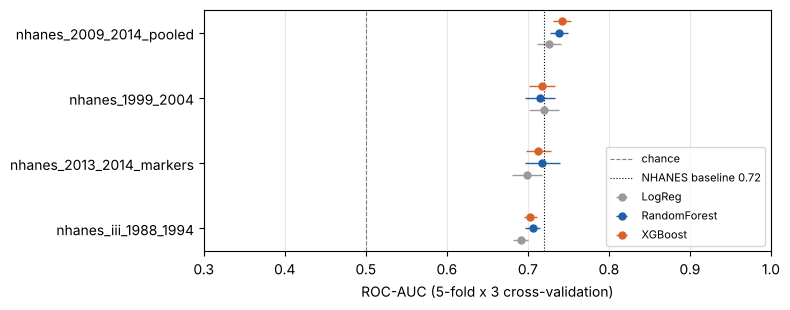

In [10]:
# ROC-AUC per dataset and model (error bars: SD over the 15 CV folds)
import matplotlib.pyplot as plt
r = res[res.best_auc.notna()].sort_values('best_auc')
if len(r):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(r) + 1.2))
    for k, (m, c) in enumerate([('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]):
        ax.errorbar(r[f'{m}_auc'], [i + (k - 1) * 0.18 for i in range(len(r))], xerr=r[f'{m}_sd'], fmt='o', ms=5,
                    color=c, label=m, elinewidth=1)
    ax.axvline(0.5, ls='--', color='grey', lw=0.8, label='chance')
    ax.axvline(0.72, ls=':', color='black', lw=0.8, label='NHANES baseline 0.72')
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.dataset)
    ax.set_xlabel('ROC-AUC (5-fold x 3 cross-validation)'); ax.set_xlim(0.3, 1.0)
    ax.legend(loc='lower right', fontsize=8); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout(); plt.show()